# Step 4. Which reader, and with which rules?

**The question.** Step 2 left a hypothesis (a vision-language model reading the whole page finds far more
question numbers than any reader of single lines) that could not be trusted, because it was seen on Mendeley
exams. This chapter makes every choice of the reader again, on the development set of step 3:

    Part 1  Which model reads       five readers: TrOCR base and large on the detected lines, Qwen3-VL-2B on the
                                    lines, and Qwen3-VL-2B and 4B on the whole page
    Part 2  Where they go wrong     the error per page, so a mean does not hide a few disasters
    Part 3  Line boxes for TrOCR    cut tall boxes into rows, or read them as detected
    Part 4  Question numbers        the stray-mark prefix of the number rule, on and off
    Part 5  Blank pages and loops   the ink threshold, and the decoding setting that stops the model looping
    Part 6  Save                    the tables, the choices, and every line every try read

Each choice is written into `vision/reader.py` by hand, with a comment pointing back here. Reads are cached per
image and setting (`vision/metrics.py`): the first run takes about an hour on an Apple GPU, later runs a minute.
Run with `uv run python -m vision.step4_choose_reader`.

In [1]:
import json
import re
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from vision import datasets, devset, eda, metrics, reader  # noqa: E402
from vision.metrics import LINE_MODELS, PAGE_MODELS, read_lines, read_page  # noqa: E402

pd.set_option("display.width", 140)
OUT = datasets.ARTIFACTS / "step4_choose_reader"
# The page reader the product uses, and the one Parts 4 and 5 look at (chosen in Part 1).
PAGE_LABEL = "Qwen3-VL-2B, page"
DECODING = {"greedy": {}, "repetition_penalty 1.02": {"repetition_penalty": 1.02},
            "repetition_penalty 1.05": {"repetition_penalty": 1.05}}
CHOSEN_GENERATE = dict(reader.VLM_GENERATE)  # the decoding chosen in Part 5, as written in reader.py

dev = devset.build()
dev["ink"] = [reader.ink(reader.load_pages(p)[0]) for p in dev["image"]]
eda.show(dev.groupby("kind", sort=False).size().rename("images"), "The development set (step 3):")


The development set (step 3):


kind
smhd           39
asap           40
notebook       12
answersheet    21
short          10
blank           4
Name: images, dtype: int64

## Part 1. Which model reads?

Three numbers per reader, all from `vision/metrics.py`: the **character error rate** on each kind of text, the
share of **question numbers found** (with the reader's own rule, `reader.assign_lines`), and the **lines invented**
on short and blank pages. Speed is the median seconds per image on an Apple GPU.

- **TrOCR** (base, large) is the text recogniser of step 1's reader: it reads one cropped line at a time, so it
  depends on the line detector.
- **Qwen3-VL** is a vision-language model (the kind Session 10 calls through an API, run locally here, no key).
  It can read the cropped lines too, or the whole page at once, which needs no detector at all.

In [2]:
rows = {label: {**metrics.score(dev, lambda r, label=label: [tuple(x) for x in read_lines(label, r.image)["lines"]]),
                "seconds_per_image": np.median([read_lines(label, p)["seconds"] for p in dev["image"]])}
        for label in LINE_MODELS}
for label, model in PAGE_MODELS.items():
    rows[label] = {**metrics.score(dev, lambda r, model=model: read_page(r.image, CHOSEN_GENERATE, model)),
                   "seconds_per_image": np.nanmedian([metrics.page_seconds(p, CHOSEN_GENERATE, model) for p in dev["image"]])}
reader.PAGE_READER = PAGE_MODELS[PAGE_LABEL]
readers = pd.DataFrame(rows).T.sort_values("cer_smhd")
eda.show(readers, "Every reader on the development set (lower error is better, more numbers found is better):")


Every reader on the development set (lower error is better, more numbers found is better):


,cer_smhd,cer_asap,cer_notebook,numbers_found_smhd,numbers_found_notebook,numbers_found_answersheet,extra_numbers_per_page,invented_lines,seconds_per_image
"Qwen3-VL-4B, page",0.065,0.013,0.040,0.847,1.000,0.458,0.205,13.0,10.360
"Qwen3-VL-2B, page",0.073,0.017,0.051,0.893,1.000,0.429,0.273,12.0,10.425
"Qwen3-VL-2B, lines",0.189,0.156,0.319,0.559,0.833,0.076,0.114,4.0,5.590
"TrOCR large, lines",0.221,0.212,0.453,0.304,0.250,0.025,0.000,4.0,2.645
"TrOCR base, lines",0.276,0.227,0.509,0.234,0.000,0.000,0.114,4.0,1.660


**Reading the whole page wins by a wide margin.** Qwen3-VL-2B on the page reads SMHD with 7% character error,
against 19% for the same model on cropped lines and 22 to 28% for TrOCR, and finds 89% of the numbered lines'
numbers, against 23 to 56%. The line readers lose twice: the line detector cuts or merges lines, and a single
line has no context to read a word from. The 4B model reads slightly better (6.5%) but finds fewer numbers
(85%), and with twice the parameters it needs more memory than a free Hugging Face Space has (the 2B model
already peaks at 13 GB on CPU). **The product uses
Qwen3-VL-2B on the whole page**; 4B stays as a documented try (it is evaluated again in step 7).

## Part 2. Where the readers go wrong

A mean error can hide a few pages read completely wrong. The error per page shows whether the page reader is
better everywhere or only on average.


Character error per page: median and 90th percentile


0.5                    0.9                
kind                 asap notebook   smhd   asap notebook   smhd
reader                                                          
Qwen3-VL-2B, lines  0.093    0.293  0.163  0.279    0.489  0.295
Qwen3-VL-2B, page   0.011    0.045  0.061  0.042    0.091  0.112
Qwen3-VL-4B, page   0.009    0.031  0.055  0.033    0.080  0.109
TrOCR base, lines   0.116    0.506  0.278  0.628    0.629  0.414
TrOCR large, lines  0.126    0.442  0.231  0.612    0.605  0.318

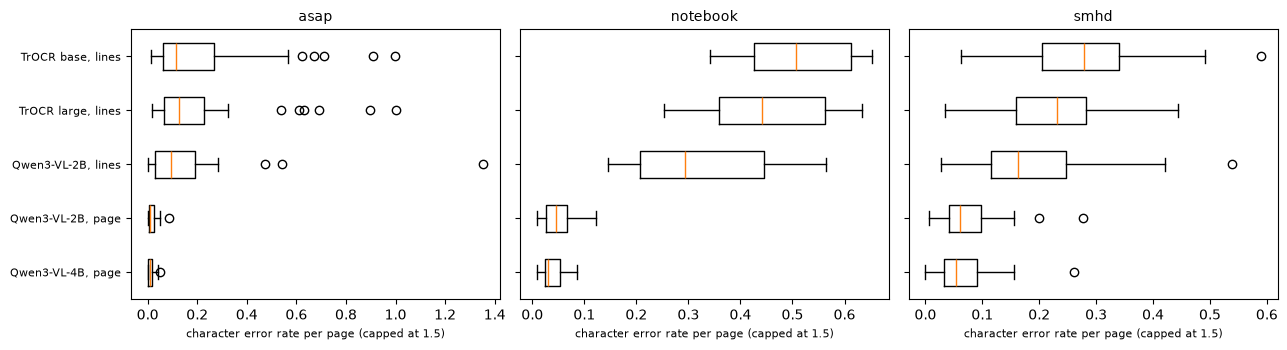

figure: error_per_page.png


In [3]:


def per_page_errors(label: str) -> pd.DataFrame:
    if label in LINE_MODELS:
        lines_of = lambda r: [tuple(x) for x in read_lines(label, r.image)["lines"]]  # noqa: E731
    else:
        lines_of = lambda r: read_page(r.image, CHOSEN_GENERATE, PAGE_MODELS[label])  # noqa: E731
    text = dev[dev["kind"].isin(["smhd", "asap", "notebook"])]
    return pd.DataFrame({"reader": label, "kind": text["kind"],
                         "cer": [metrics.cer("\n".join(t for t, _ in lines_of(r)), r.truth) for r in text.itertuples()]})


errors = pd.concat([per_page_errors(label) for label in readers.index])
eda.show(errors.groupby(["reader", "kind"])["cer"].quantile([0.5, 0.9]).unstack().unstack(),
         "Character error per page: median and 90th percentile")
plt = eda.plt()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (kind, part) in zip(axes, errors.groupby("kind")):
    order = readers.index.tolist()
    ax.boxplot([part.loc[part["reader"] == r, "cer"].clip(upper=1.5) for r in order], orientation="horizontal")
    ax.set_yticks(range(1, len(order) + 1), order, fontsize=8)
    ax.set_title(kind, fontsize=10)
    ax.set_xlabel("character error rate per page (capped at 1.5)", fontsize=8)
eda.save_figure(fig, OUT / "error_per_page.png")

The page reader is better on almost every page, not only on average: its 90th percentile is below the other
readers' medians on SMHD and notebooks. Its worst pages are the ones to keep in mind for review in the product.

## Part 3. Line boxes for TrOCR

The `ocr` mode (the line detector and TrOCR) stays in the product as the baseline the page reader is compared
against, so it should be as good as it can be. A line box much taller than a normal line usually holds two lines
written close together, and TrOCR reads one line per crop. Cutting such a box into rows at the emptiest band is
compared with reading it as detected.

In [4]:
reader.SPLIT_TALL = False
unsplit = metrics.score(dev, lambda r: [tuple(x) for x in read_lines("TrOCR base, lines", r.image)["lines"]])
reader.SPLIT_TALL = True
split_table = pd.DataFrame({"cut tall boxes": rows["TrOCR base, lines"], "as detected": unsplit}).T
eda.show(split_table[["cer_smhd", "cer_asap", "cer_notebook"]], "TrOCR base, with tall boxes cut or as detected:")


TrOCR base, with tall boxes cut or as detected:


,cer_smhd,cer_asap,cer_notebook
cut tall boxes,0.276,0.227,0.509
as detected,0.281,0.247,0.575


Cutting tall boxes lowers TrOCR's error slightly on SMHD, so the `ocr` mode keeps it (`reader.SPLIT_TALL`).

## Part 4. Question numbers: the stray-mark prefix

The rule that recognises a question number at the start of a line (`reader.LEADING_NUMBER`) accepts up to three
stray marks before the digits (a quote, a bracket, or one letter stuck to them as in "p16."). Readers often
write such a mark for the margin of the page. Three other rules were tried on this set and removed because they
found no more numbers: repairing a misread number from the sequence, splitting a line at a later number, and
accepting a number with no separator after it.

In [5]:
with_prefix = reader.LEADING_NUMBER
reader.LEADING_NUMBER = re.compile(with_prefix.pattern.replace(r"^\W{0,3}(?:(?:q|question|ex|exercise)\s*\.?\s*|[a-z](?=\d))?",
                                                               r"^\s*(?:(?:q|question|ex|exercise)\s*\.?\s*)?"), re.IGNORECASE)
without = metrics.score(dev, lambda r: read_page(r.image, CHOSEN_GENERATE))
reader.LEADING_NUMBER = with_prefix
rules = pd.DataFrame({"with prefix": rows[PAGE_LABEL], "without prefix": without}).T
eda.show(rules[["numbers_found_smhd", "numbers_found_notebook", "numbers_found_answersheet", "extra_numbers_per_page"]],
         "Question numbers found, with and without the stray-mark prefix:")


Question numbers found, with and without the stray-mark prefix:


,numbers_found_smhd,numbers_found_notebook,numbers_found_answersheet,extra_numbers_per_page
with prefix,0.893,1.0,0.429,0.273
without prefix,0.845,1.0,0.405,0.273


The prefix finds more numbers on SMHD (89% against 84%) without reading more extra ones, so it stays.

## Part 5. Blank pages, and decoding loops

**Blank pages.** Step 3 measured the ink of every page. The threshold is set at half the lightest written page,
so every written page is read and every blank page is skipped, with a margin on both sides.

**Loops.** With plain greedy decoding a vision-language model can fall into a loop on a page with little
writing ("Cell", "Cell", "Cell"...). A repetition penalty makes a token that was just written less likely to be
written again. Too strong a penalty could also stop the model writing a word that really repeats, so two small
values are compared with none.

In [6]:
written, blank = dev.loc[dev["kind"] != "blank", "ink"], dev.loc[dev["kind"] == "blank", "ink"]
blank_ink = round(float(written.min()) / 2, 4)  # half the lightest written page
assert blank.max() < blank_ink, "a blank page has more ink than the threshold"
print(f"ink: blank pages up to {blank.max():.4f}, written pages from {written.min():.4f} -> threshold {blank_ink}")

ink: blank pages up to 0.0000, written pages from 0.0020 -> threshold 0.001


In [7]:
decoding = pd.DataFrame({name: metrics.score(dev, lambda r, g=g: read_page(r.image, g)) for name, g in DECODING.items()}).T
reader.VLM_GENERATE = CHOSEN_GENERATE
eda.show(decoding, "The page reader with three decoding settings:")


The page reader with three decoding settings:


,cer_smhd,cer_asap,cer_notebook,numbers_found_smhd,numbers_found_notebook,numbers_found_answersheet,extra_numbers_per_page,invented_lines
greedy,0.071,0.017,0.047,0.889,1.0,0.476,0.295,703.0
repetition_penalty 1.02,0.072,0.017,0.050,0.889,1.0,0.417,0.273,12.0
repetition_penalty 1.05,0.073,0.017,0.051,0.893,1.0,0.429,0.273,12.0


Greedy decoding wrote 703 lines that are not on the short and blank pages. Either penalty brings that to 12
without raising the error rate by more than half a point; 1.05 finds slightly more numbers than 1.02 (89.3%
against 88.9% on SMHD, 43% against 42% on answer sheets), so it is the product's setting (`reader.VLM_GENERATE`).
Greedy finds the most numbers on answer sheets (48%), but 703 invented lines would put invented answers in
front of the grader, which is worse than a missed number. The blank threshold is 0.001 (`reader.BLANK_INK`).

## Part 6. Save

The tables above, the choices, and every line every try read (public data only), so each number can be checked.

In [8]:
readers.to_csv(OUT / "dev_readers.csv")
split_table.to_csv(OUT / "dev_line_boxes.csv")
rules.to_csv(OUT / "dev_number_rule.csv")
decoding.to_csv(OUT / "dev_decoding.csv")
choices = {"reader": PAGE_LABEL, "lowest_error_rate": readers.index[0], "blank_ink": blank_ink,
           "generate": CHOSEN_GENERATE, "dev_set": dev.groupby("kind").size().to_dict()}
(OUT / "dev_choices.json").write_text(json.dumps(choices, indent=2))
print(json.dumps(choices, indent=2))

{
  "reader": "Qwen3-VL-2B, page",
  "lowest_error_rate": "Qwen3-VL-4B, page",
  "blank_ink": 0.001,
  "generate": {
    "repetition_penalty": 1.05
  },
  "dev_set": {
    "answersheet": 21,
    "asap": 40,
    "blank": 4,
    "notebook": 12,
    "short": 10,
    "smhd": 39
  }
}


In [9]:
tries = {label: lambda r, label=label: [tuple(x) for x in read_lines(label, r.image)["lines"]] for label in LINE_MODELS}
reader.SPLIT_TALL = False
as_detected = {r.image: [tuple(x) for x in read_lines("TrOCR base, lines", r.image)["lines"]] for r in dev.itertuples()}
reader.SPLIT_TALL = True
tries["TrOCR base, lines as detected"] = lambda r: as_detected[r.image]
tries |= {f"{label}, {name}": lambda r, m=model, g=g: read_page(r.image, g, m)
          for label, model in PAGE_MODELS.items() for name, g in DECODING.items()
          if model == PAGE_MODELS[PAGE_LABEL] or g == CHOSEN_GENERATE}
dump = []
for name, lines_of in tries.items():
    for r in dev.itertuples():
        dump += [{"try": name, "kind": r.kind, "image": Path(r.image).name, "line": k, "text": text, "confidence": conf}
                 for k, (text, conf) in enumerate(lines_of(r), start=1)]
pd.DataFrame(dump).to_csv(OUT / "dev_reads.csv", index=False)
print(f"saved {len(dump)} read lines from {len(tries)} tries")

saved 11722 read lines from 8 tries


## Conclusion, and why it leads to step 5

The product reader is **Qwen3-VL-2B reading the whole page**, with a repetition penalty of 1.05, no blank pages
sent to it, and question numbers recognised at the start of a line after up to three stray marks. Every one of
those choices was made on public data, so the Mendeley exams are still unseen.

One number stands out: on the **answer sheets**, the pages most like the product's exams, the reader finds only
43% of the question numbers, against 89% on SMHD's numbered lists. The model was never trained on exam answer
sheets. The natural next try is to **fine-tune it on exam-like pages**, which needs training data that is not in
the development set and not from Mendeley: step 5 builds it.